# 04 — Arbitrary separable shapes & differentiability

Phase 4 — the payoff of the method: **any separable bispectrum** can be generated. We show:
1. the **oscillatory feature** template (Planck Eq. 15): $B=6f_{\rm NL}[P_1P_2P_3]^{2/3}\sin(\omega(k_1+k_2+k3))$;
2. the **equilateral-feature** (Planck Eq. 18): $B^{\rm feat\text{-}eq}=S^{\rm eq}\times B^{\rm feat}$, which suppresses the (unphysical) squeezed limit. Under scale invariance $S^{\rm eq}\,6[P]^{2/3}=B^{\rm eq}$, so this is just **the equilateral template $\times\sin$**, built with `modulate_sin(equilateral(n_s),\omega)`;
3. **autodiff** — gradients of the field w.r.t. $\omega$ and the white-noise field.

Fields are cached (`cache_04_fields.npz`); set `REGEN=True` to rebuild. Kernel **Python (jaxpng)**.

In [1]:
import os
import numpy as np
import jax, jax.numpy as jnp
import matplotlib.pyplot as plt
import jaxpng
from jaxpng import cosmology as C, gaussian, bispectra as B, phing, measure, api
from jaxpng.config import Box
TK='../../gengars/inputs/planck18_transfer.dat'
cosmo=C.make_cosmo(TK, omega_m=0.3175, omega_l=0.6825, omega_b=0.049,
                   hubble=0.6711, n_s=0.9624, sigma8=0.834, sigma8_norm=True)
n_s=cosmo.n_s; box=Box(N=64, L=1000.0)
omega=20.0; fNL=100.0; nreal=10; per_efold=12.0
CACHE='cache_04_fields.npz'; REGEN=False
tmpl_feat = B.feature(n_s, omega)                       # 6[P]^2/3 sin(w Sk)          (4 terms)
tmpl_eqf  = B.modulate_sin(B.equilateral(n_s), omega)   # B^eq_template x sin = Planck Eq.18 (40 terms)
print('jax', jax.__version__, '| N_terms feature=%d  eq-feature=%d'%(len(tmpl_feat),len(tmpl_eqf)))

jax 0.10.1 | N_terms feature=4  eq-feature=40


## Generate (or load) the fields  Φ^G, Φ^NG[feature], Φ^NG[eq-feature]

In [2]:
keys=jax.random.split(jax.random.PRNGKey(1), nreal)
if (not REGEN) and os.path.exists(CACHE):
    d=np.load(CACHE)
    phiG=jnp.asarray(d['phiG']); ng_feat=jnp.asarray(d['ng_feat']); ng_eqf=jnp.asarray(d['ng_eqf'])
    print('loaded cache: %.0f MB'%(os.path.getsize(CACHE)/1e6))
else:
    pg=[]; nf=[]; ne=[]
    for key in keys:
        g=gaussian.phiG_from_white_noise(jax.random.normal(key, box.rshape), cosmo, box)
        pg.append(g)
        nf.append(phing.phiNG(g, tmpl_feat, box, n_s, per_efold=per_efold))
        ne.append(phing.phiNG(g, tmpl_eqf , box, n_s, per_efold=per_efold))
    phiG=jnp.stack(pg); ng_feat=jnp.stack(nf); ng_eqf=jnp.stack(ne)
    np.savez(CACHE, phiG=np.asarray(phiG), ng_feat=np.asarray(ng_feat), ng_eqf=np.asarray(ng_eqf))
    print('generated + saved: %.0f MB'%(os.path.getsize(CACHE)/1e6))
th=measure.EQUILATERAL_THETA
def paired(ngal, ks, squeezed_k1=None):
    out=np.zeros((nreal,len(ks)))
    for r in range(nreal):
        phi=phiG[r]+fNL*ngal[r]; pg=phiG[r]
        for j,k in enumerate(ks):
            if squeezed_k1 is None: a,b,tt=float(k),float(k),th
            else: a,b,tt=squeezed_k1,float(k),float(np.arccos(-squeezed_k1/(2*k)))
            out[r,j]=float(measure.bispectrum(phi,box.L,a,b,tt)['B'][0]-measure.bispectrum(pg,box.L,a,b,tt)['B'][0])
    return out.mean(0), out.std(0)/np.sqrt(nreal)

generated + saved: 65 MB


## 1. Oscillatory feature ($\omega=20$): field slice + equilateral $B(k)\propto\sin(3\omega k)$

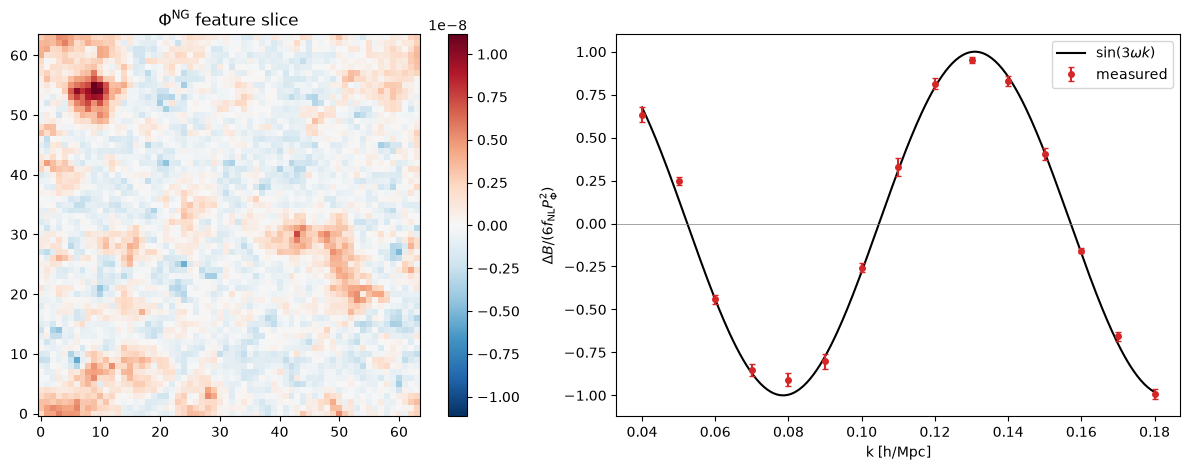

In [3]:
ngx=np.asarray(jnp.fft.irfftn(ng_feat[0], s=box.rshape))
keq=np.linspace(0.04,0.18,15); m,e=paired(ng_feat, keq)
Pk=np.asarray(C.power_phi(cosmo, jnp.asarray(keq))); ratio=m/(6*fNL*Pk**2); err=e/(6*fNL*Pk**2)
fig,ax=plt.subplots(1,2,figsize=(13,4.8))
sl=ngx[box.N//2]; v=np.max(np.abs(sl))
im=ax[0].imshow(sl,origin='lower',cmap='RdBu_r',vmin=-v,vmax=v); ax[0].set_title('$\\Phi^{\\rm NG}$ feature slice'); plt.colorbar(im,ax=ax[0],fraction=0.046)
kk=np.linspace(keq[0],keq[-1],300)
ax[1].plot(kk, np.sin(3*omega*kk),'k-',label='$\\sin(3\\omega k)$')
ax[1].errorbar(keq, ratio, yerr=err, fmt='C3o', ms=4, capsize=2, label='measured')
ax[1].set_xlabel('k [h/Mpc]'); ax[1].set_ylabel('$\\Delta B/(6 f_{\\rm NL}P_\\Phi^2)$'); ax[1].legend(); ax[1].axhline(0,color='gray',lw=.5)
plt.tight_layout(); plt.show()

## 2. Equilateral-feature (Planck Eq. 18) — same equilateral amplitude, squeezed suppressed
$B^{\rm feat\text{-}eq}=B^{\rm eq}\times\sin(\omega\Sigma k)$. **Left:** equilateral $B(k)$ still $\propto\sin(3\omega k)$ (since $S^{\rm eq}=1$ at equilateral, the amplitude is preserved). **Right:** in the squeezed limit the equilateral-feature is **suppressed** relative to the bare feature (ratio $\to S^{\rm eq}\to0$), consistent with single-field consistency relations.

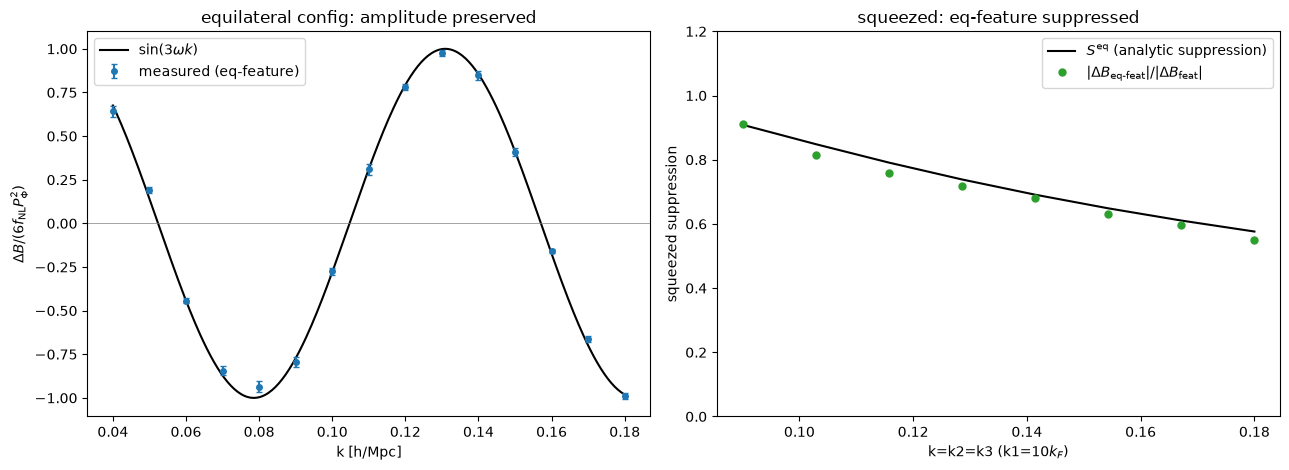

squeezed |B_eqfeat|/|B_feat| : [0.91 0.82 0.76 0.72 0.68 0.63 0.6  0.55]  vs S^eq [0.91 0.85 0.79 0.74 0.69 0.65 0.61 0.58]


In [4]:
keq=np.linspace(0.04,0.18,15); m_eqf,e_eqf=paired(ng_eqf, keq)
Pk=np.asarray(C.power_phi(cosmo, jnp.asarray(keq))); ratio=m_eqf/(6*fNL*Pk**2); err=e_eqf/(6*fNL*Pk**2)
k1sq=10*box.dk; ksq=np.linspace(0.09,0.18,8)
sf,_=paired(ng_feat, ksq, squeezed_k1=k1sq); se,_=paired(ng_eqf, ksq, squeezed_k1=k1sq)
Seq=np.array([float(B.equilateral_shape_value(k1sq,k,k)) for k in ksq])
fig,ax=plt.subplots(1,2,figsize=(13,4.8))
kk=np.linspace(keq[0],keq[-1],300)
ax[0].plot(kk, np.sin(3*omega*kk),'k-',label='$\\sin(3\\omega k)$')
ax[0].errorbar(keq, ratio, yerr=err, fmt='C0o', ms=4, capsize=2, label='measured (eq-feature)')
ax[0].set_xlabel('k [h/Mpc]'); ax[0].set_ylabel('$\\Delta B/(6 f_{\\rm NL}P_\\Phi^2)$'); ax[0].legend(); ax[0].axhline(0,color='gray',lw=.5)
ax[0].set_title('equilateral config: amplitude preserved')
ax[1].plot(ksq, Seq, 'k-', label='$S^{\\rm eq}$ (analytic suppression)')
ax[1].errorbar(ksq, np.abs(se)/np.abs(sf), yerr=None, fmt='C2o', ms=5, label='$|\\Delta B_{\\rm eq\\text{-}feat}|/|\\Delta B_{\\rm feat}|$')
ax[1].set_xlabel('k=k2=k3 (k1=10$k_F$)'); ax[1].set_ylabel('squeezed suppression'); ax[1].legend(); ax[1].set_ylim(0,1.2)
ax[1].set_title('squeezed: eq-feature suppressed')
plt.tight_layout(); plt.show()
print('squeezed |B_eqfeat|/|B_feat| :', np.round(np.abs(se)/np.abs(sf),2), ' vs S^eq', np.round(Seq,2))

## 3. Differentiability (autodiff)
`jax.grad` flows through the Schwinger `lax.scan`: $d/d\omega$ of a summary vs finite difference, and the gradient w.r.t. the **white-noise field** (an $N^3$ object — what field-level HMC needs).

d(summary)/d(omega) [eq-feature]:  autodiff=-1.449489e-05  finite-diff=-1.449489e-05  ratio=1.0000


grad wrt white noise: (32, 32, 32) | finite: True


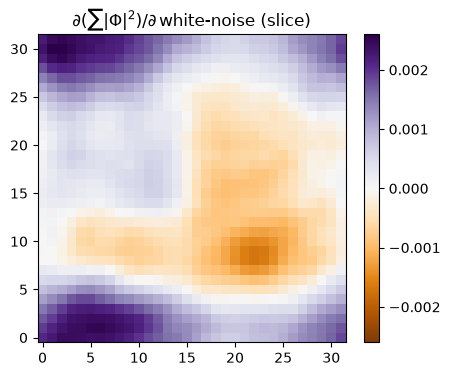

In [5]:
boxs=Box(N=32, L=1000.0); ws=jax.random.normal(jax.random.PRNGKey(5), boxs.rshape)
def summary_omega(om):
    return jnp.sum(jnp.abs(api.generate_phi(ws, cosmo, boxs, B.modulate_sin(B.equilateral(n_s), om), n_s, 100.0, per_efold=10.0))**2)
g_ad=float(jax.grad(summary_omega)(20.0)); h=1e-3
g_fd=float((summary_omega(20.0+h)-summary_omega(20.0-h))/(2*h))
print('d(summary)/d(omega) [eq-feature]:  autodiff=%.6e  finite-diff=%.6e  ratio=%.4f'%(g_ad,g_fd,g_ad/g_fd))
def summary_w(wn):
    return jnp.sum(jnp.abs(api.generate_phi(wn, cosmo, boxs, B.feature(n_s,omega), n_s, 100.0, per_efold=10.0))**2)
gw=jax.grad(summary_w)(ws); print('grad wrt white noise:', gw.shape, '| finite:', bool(jnp.all(jnp.isfinite(gw))))
plt.figure(figsize=(4.6,4)); sl=np.asarray(gw[boxs.N//2]); v=np.max(np.abs(sl))
plt.imshow(sl,origin='lower',cmap='PuOr',vmin=-v,vmax=v); plt.title(r'$\partial(\sum|\Phi|^2)/\partial\,$white-noise (slice)'); plt.colorbar(fraction=0.046); plt.show()

**Phase 4 OK**: arbitrary separable shapes generate the correct bispectrum; the equilateral-feature (equilateral template $\times\sin$ = Planck Eq. 18) preserves the equilateral amplitude while suppressing the squeezed limit; and the generator is differentiable end-to-end (matches finite differences).